# Flexible Uncertainty Estimation with MLPs: Ensemble, MC Dropout, Max Probability

This tutorial demonstrates how to use the same MLP model for different uncertainty estimation techniques (ensemble, MC dropout, max probability) on a synthetic 3-arm spiral dataset. The code is designed to be flexible for adding new metrics and supports multiple scores per technique.

---

## 1. Import Required Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from collections import defaultdict
import random

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

# Good color palette
amber = [230/255, 159/255, 0/255]      # #E69F00
cyan = [86/255, 180/255, 233/255]      # #56B4E9
green = [0/255, 158/255, 115/255]      # #009E73
yellow = [240/255, 228/255, 66/255]    # #F0E442
navy = [0/255, 114/255, 178/255]       # #0072B2
red = [213/255, 94/255, 0/255]         # #D55E00
pink = [204/255, 121/255, 167/255]     # #CC79A7
cmap = [amber, cyan, green, yellow, navy, red, pink]
bg_theme = 'dark' #  'black', 'white', 'dark', 'light'
if bg_theme in ['black','dark']:
    plt.style.use('dark_background')
else:
    plt.rcdefaults()

# 2. Generate Synthetic Data

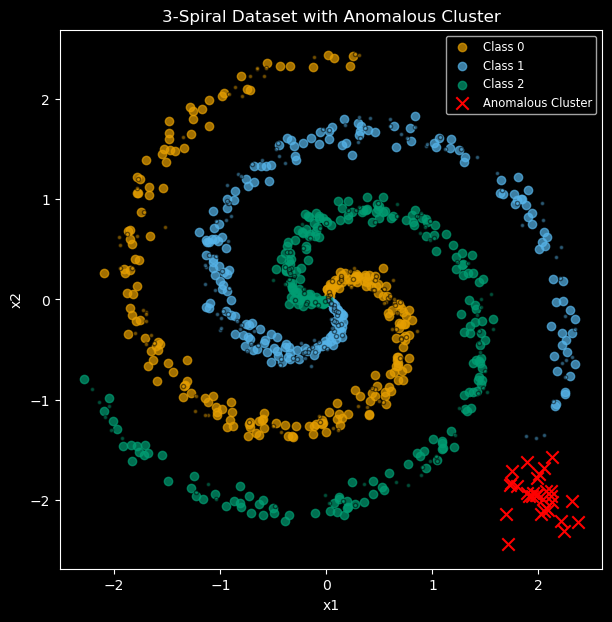

In [2]:
def generate_spiral(n_samples, n_arms, noise=0.2):
    X = []
    y = []
    # Calculate angle between arms in radians (2π/n_arms)
    angle_between_arms = 2 * np.pi / n_arms
    
    for j in range(n_arms):
        ix = np.arange(n_samples)
        r = ix / n_samples  # radius increases linearly with index
        # Distribute arms evenly by multiplying by angle_between_arms
        t = j * angle_between_arms + r * 2 * np.pi + np.random.randn(n_samples) * noise
        x1 = r * np.sin(t)
        x2 = r * np.cos(t)
        X += list(np.c_[x1, x2])
        y += [j] * n_samples
        
    anom_X = np.array([2., -2.]) + np.random.randn(30, 2) * 0.2
    return np.array(X), np.array(y), anom_X

def generate_moons_with_anomalies(n_samples):
    from sklearn.datasets import make_moons
    X, y = make_moons(n_samples=500, noise=0.1, random_state=42)
    # Generate anomalous cluster
    anom_X = np.array([2., 2.]) + np.random.randn(30, 2) * 0.2
    return X, y, anom_X

# Choose dataset type (uncomment one)
n_samples = 300
# ---- Option 1: Spiral dataset ----
num_classes = 3
X_all, y_all, anom_X = generate_spiral(n_samples, num_classes)

# ---- Option 2: Two moons dataset ----
# num_classes = 2
# X_all, y_all, anom_X = generate_moons_with_anomalies(n_samples)

# Common preprocessing for both datasets
scaler = StandardScaler()
X_all = scaler.fit_transform(X_all)
X_anom = scaler.transform(anom_X)

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.3, random_state=42)


plt.figure(figsize=(7,7))
for i in range(num_classes):
    plt.scatter(X_train[y_train==i,0], X_train[y_train==i,1], label=f"Class {i}", alpha=0.7, color=cmap[i])
for i in range(num_classes):
    plt.scatter(X_test[y_test==i,0], X_test[y_test==i,1], marker='.', edgecolor='black', alpha=0.5, color=cmap[i])
plt.scatter(anom_X[:,0], anom_X[:,1], c='red', marker='x', label='Anomalous Cluster', s=80)
plt.legend(loc='upper right', fontsize='small')
plt.title(f"{num_classes}-Spiral Dataset with Anomalous Cluster")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()


# 3. Build MLP Model

In [3]:
class FlexibleMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, output_dim, dropout=0.0):
        super().__init__()
        self.layers = nn.ModuleList()
        self.activations = []
        self.dropouts = []
        last_dim = input_dim
        for h in hidden_dims:
            self.layers.append(nn.Linear(last_dim, h))
            self.activations.append(nn.GELU())
            self.dropouts.append(nn.Dropout(dropout) if dropout > 0 else nn.Identity())
            last_dim = h
        self.out_layer = nn.Linear(last_dim, output_dim)
        self._init_weights()

    def _init_weights(self):
        for layer in self.layers:
            nn.init.xavier_uniform_(layer.weight)
            if layer.bias is not None:
                nn.init.zeros_(layer.bias)
        nn.init.xavier_uniform_(self.out_layer.weight)
        if self.out_layer.bias is not None:
            nn.init.zeros_(self.out_layer.bias)

    def forward(self, x):
        for i, (layer, act, drop) in enumerate(zip(self.layers, self.activations, self.dropouts)):
            residual = x
            x = layer(x)
            x = act(x)
            x = drop(x)
            # Add residual connection if dimensions match
            if residual.shape == x.shape:
                x = x + residual
        x = self.out_layer(x)
        return x

# Example usage:
# model = FlexibleMLP(input_dim=2, hidden_dims=[64, 64], output_dim=3, dropout=0.2)

# Training loops

In [4]:
def train_ensemble(X_train, y_train, n_models=5, epochs=100, lr=0.01, hidden_dims=[64,64], dropout=0.0):
    models = []
    for i in range(n_models):
        model = FlexibleMLP(2, hidden_dims, num_classes, dropout)
        optimizer = optim.Adam(model.parameters(), lr=lr)
        criterion = nn.CrossEntropyLoss()
        X_t = torch.tensor(X_train, dtype=torch.float32)
        y_t = torch.tensor(y_train, dtype=torch.long)
        for epoch in range(epochs):
            optimizer.zero_grad()
            out = model(X_t)
            loss = criterion(out, y_t)
            loss.backward()
            optimizer.step()
        models.append(model)
    return models

def ensemble_predict(models, X):
    X_t = torch.tensor(X, dtype=torch.float32)
    preds = []
    for model in models:
        with torch.no_grad():
            logits = model(X_t)
            probs = F.softmax(logits, dim=1).cpu().numpy()
            preds.append(probs)
    preds = np.stack(preds)  # shape: (n_models, n_samples, n_classes)
    mean_probs = np.mean(preds, axis=0)
    var_probs = np.var(preds, axis=0)
    entropy = -np.sum(mean_probs * np.log(mean_probs + 1e-8), axis=1)
    return mean_probs, var_probs, entropy

In [5]:
def mc_dropout_predict(model, X, n_passes=20):
    model.train()  # Enable dropout
    X_t = torch.tensor(X, dtype=torch.float32)
    preds = []
    for _ in range(n_passes):
        with torch.no_grad():
            logits = model(X_t)
            probs = F.softmax(logits, dim=1).cpu().numpy()
            preds.append(probs)
    preds = np.stack(preds)  # shape: (n_passes, n_samples, n_classes)
    mean_probs = np.mean(preds, axis=0)
    var_probs = np.var(preds, axis=0)
    entropy = -np.sum(mean_probs * np.log(mean_probs + 1e-8), axis=1)
    return mean_probs, var_probs, entropy

def baseline_predict(model, X):
    model.eval()  # Disable dropout
    X_t = torch.tensor(X, dtype=torch.float32)
    with torch.no_grad():
        logits = model(X_t)
        probs = F.softmax(logits, dim=1).cpu().numpy()
    return probs

In [6]:
def max_prob_metric(probs):
    # probs: (n_samples, n_classes)
    max_probs = 1 - np.max(probs, axis=1)
    return max_probs  # Higher = more confident, lower = more uncertain

In [7]:
# Train ensemble
ensemble_models = train_ensemble(X_train, y_train, n_models=5, epochs=150, lr=0.01, hidden_dims=[64,64], dropout=0.0)

# Train MC Dropout model
mc_model = FlexibleMLP(2, [64,64,64], num_classes, dropout=0.2)
optimizer = optim.Adam(mc_model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()
X_t = torch.tensor(X_train, dtype=torch.float32)
y_t = torch.tensor(y_train, dtype=torch.long)
for epoch in range(1000):
    optimizer.zero_grad()
    out = mc_model(X_t)
    loss = criterion(out, y_t)
    loss.backward()
    optimizer.step()

# 4. Useful class for handling uncertainty metrics

In [8]:
class UncertaintyScores:
    def __init__(self):
        self.scores = defaultdict(dict)  # {technique: {score_name: values}}
    def add(self, technique, score_name, values):
        self.scores[technique][score_name] = values
    def get(self, technique, score_name):
        return self.scores[technique][score_name]
    def summary(self):
        return {k: list(v.keys()) for k,v in self.scores.items()}

# Example usage:
# uscores = UncertaintyScores()
# uscores.add('ensemble', 'variance', var_probs)
# uscores.add('ensemble', 'entropy', entropy)
# uscores.add('ensemble', 'max_prob', max_probs)

In [9]:
uscores = UncertaintyScores()

# Ensemble metrics
mean_probs_e, var_probs_e, entropy_e = ensemble_predict(ensemble_models, X_test)
uscores.add('ensemble', 'variance', var_probs_e)
uscores.add('ensemble', 'entropy', entropy_e)
uscores.add('ensemble', 'max_prob', max_prob_metric(mean_probs_e))

# MC Dropout metrics
mean_probs_mc, var_probs_mc, entropy_mc = mc_dropout_predict(mc_model, X_test, n_passes=20)
uscores.add('mc_dropout', 'variance', var_probs_mc)
uscores.add('mc_dropout', 'entropy', entropy_mc)
uscores.add('mc_dropout', 'max_prob', max_prob_metric(mean_probs_mc))

# Max probability (single model)
probs = baseline_predict(mc_model, X_test)
uscores.add('single_model', 'max_prob', max_prob_metric(probs))

# Evaluate on anomalous samples
mean_probs_e_anom, var_probs_e_anom, entropy_e_anom = ensemble_predict(ensemble_models, X_anom)
mean_probs_mc_anom, var_probs_mc_anom, entropy_mc_anom = mc_dropout_predict(mc_model, X_anom, n_passes=20)
max_prob_single_anom = max_prob_metric(F.softmax(mc_model(torch.tensor(X_anom, dtype=torch.float32)), dim=1).detach().cpu().numpy())

# 5. Visualize predictions and uncertainty

In [13]:
# Visualización: fondo coloreado por incertidumbre usando un grid
def plot_grid_uncertainty(model_or_func, X_test, X_train, score_func, title, scaler, n_points=200, cmap='viridis', anom_X=None):
    # model_or_func: modelo entrenado o función de predicción
    # X: datos de test para rango
    # score_func: función que recibe X_grid y retorna score por punto
    # scaler: para desescalar si es necesario
    x_min, x_max = X_test[:,0].min()-1, X_test[:,0].max()+1
    y_min, y_max = X_test[:,1].min()-1, X_test[:,1].max()+1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, n_points), np.linspace(y_min, y_max, n_points))
    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_scaled = scaler.transform(grid)
    # grid_scaled = grid
    scores = score_func(grid_scaled)
    scores = scores.reshape(xx.shape)
    plt.figure(figsize=(8,8))
    plt.contourf(xx, yy, scores, levels=50, cmap=cmap, alpha=0.7)
    plt.scatter(X_test[:,0], X_test[:,1], c='k', s=10, label='Test samples')
    plt.scatter(X_train[:,0], X_train[:,1], c='blue', s=10, label='Train samples')
    if anom_X is not None:
        anom_scaled = scaler.transform(anom_X)
        plt.scatter(anom_scaled[:,0], anom_scaled[:,1], c='red', marker='x', s=80, label='Anomalies')
    plt.title(title)
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend()
    plt.colorbar(label='Uncertainty Score')
    plt.show()

# Ejemplo para ensemble entropy
def ensemble_entropy_grid(X_grid):
    mean_probs, _, entropy = ensemble_predict(ensemble_models, X_grid)
    return entropy

# Ejemplo para MC Dropout entropy
def mc_dropout_entropy_grid(X_grid):
    mean_probs, _, entropy = mc_dropout_predict(mc_model, X_grid, n_passes=20)
    return entropy

# Ejemplo para max prob (single model)
def max_prob_grid(X_grid):
    with torch.no_grad():
        logits = mc_model(torch.tensor(X_grid, dtype=torch.float32))
        probs = F.softmax(logits, dim=1).cpu().numpy()
    return max_prob_metric(probs)


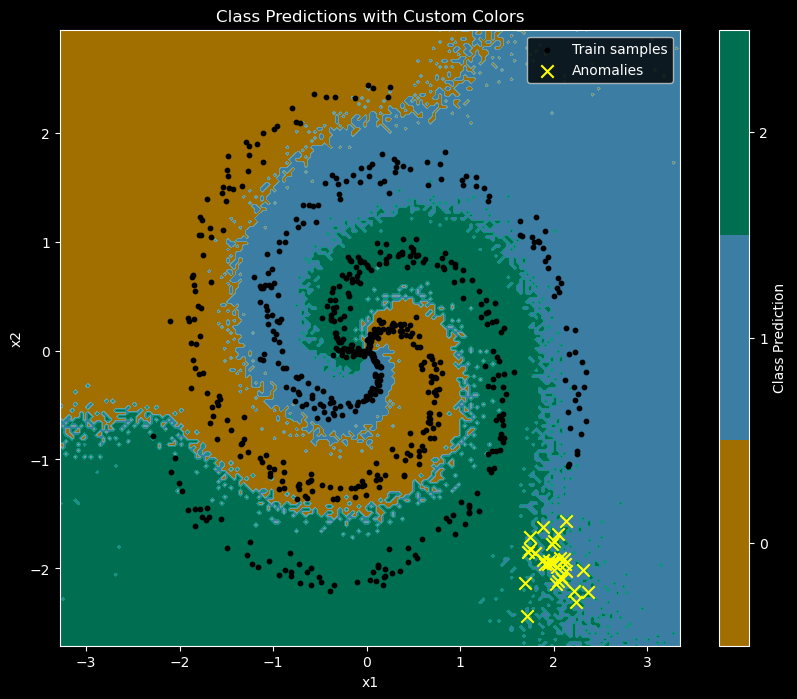

In [14]:
def plot_grid_color_class(model_or_func, X_train, X_test, title, n_points=200, anom_X=None):
    # Define custom colormap with green, blue, and red
    
    x_min, x_max = np.vstack([X_train, X_test])[:,0].min()-1, np.vstack([X_train, X_test])[:,0].max()+1
    y_min, y_max = np.vstack([X_train, X_test])[:,1].min()-0.5, np.vstack([X_train, X_test])[:,1].max()+0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, n_points), np.linspace(y_min, y_max, n_points))
    pairs = np.c_[xx.ravel(), yy.ravel()]  # Flattened grid for prediction
    probs = model_or_func(torch.tensor(pairs, dtype=torch.float32))
    preds = probs.argmax(dim=1).numpy()
    preds = preds.reshape(xx.shape)

    # Acotar custom colors al numero de clases
    custom_colors = cmap[:len(np.unique(preds))]
    custom_cmap = ListedColormap(custom_colors)
    
    plt.figure(figsize=(10,8))
    contour = plt.contourf(xx, yy, preds, levels=np.arange(len(custom_colors)+1)-0.5, cmap=custom_cmap, alpha=0.7)
    plt.scatter(X_train[:,0], X_train[:,1], c='black', s=10, label='Train samples')
    if anom_X is not None:
        plt.scatter(anom_X[:,0], anom_X[:,1], c='yellow', marker='x', s=80, label='Anomalies')
    plt.title(title)
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend()
    plt.colorbar(contour, label='Class Prediction', ticks=np.arange(len(custom_colors)))
    plt.show()

# Color by class
plot_grid_color_class(mc_model, X_train, X_test, 'Class Predictions with Custom Colors', anom_X=anom_X)


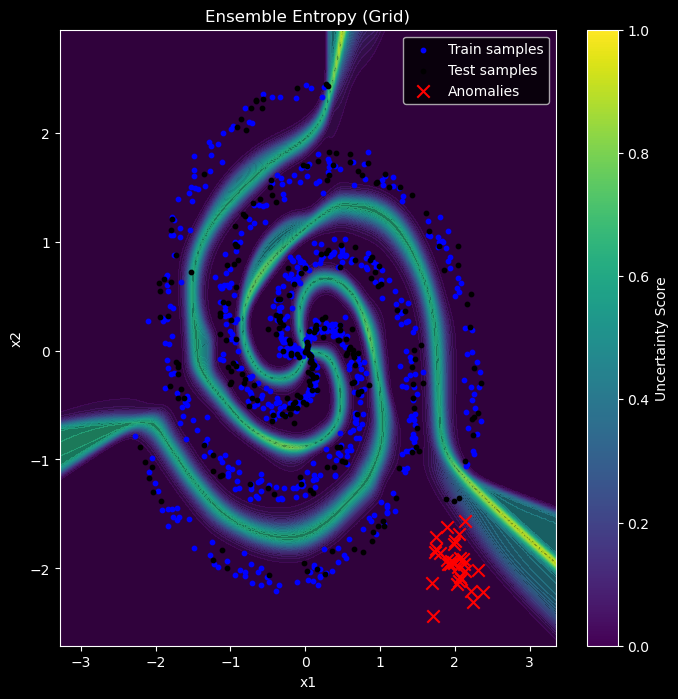

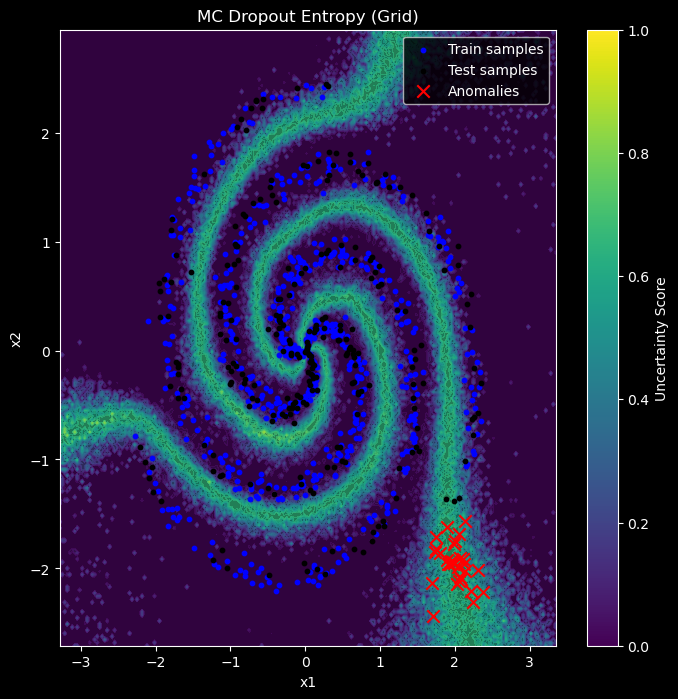

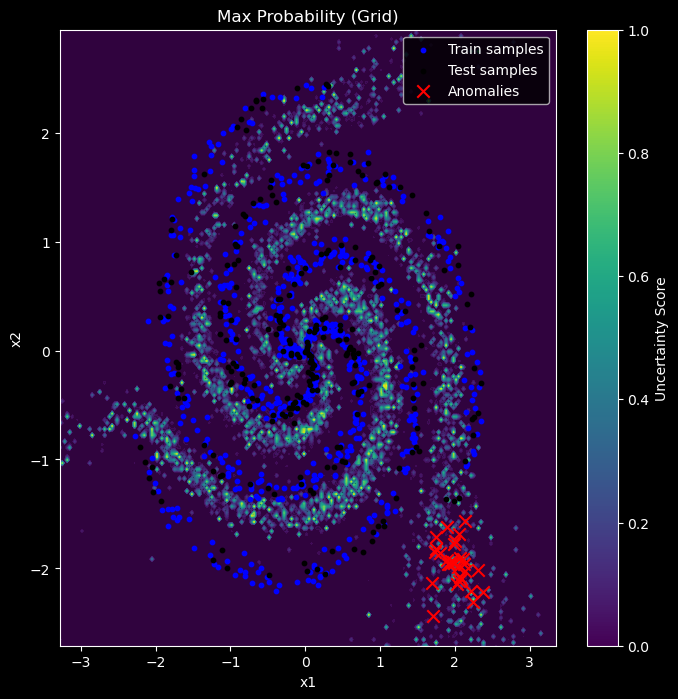

In [15]:

def plot_grid_uncertainty_split(model_or_func, X_train, X_test, score_func, title, n_points=200, cmap='viridis', anom_X=None):
    x_min, x_max = np.vstack([X_train, X_test])[:,0].min()-1, np.vstack([X_train, X_test])[:,0].max()+1
    y_min, y_max = np.vstack([X_train, X_test])[:,1].min()-0.5, np.vstack([X_train, X_test])[:,1].max()+0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, n_points), np.linspace(y_min, y_max, n_points))
    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = score_func(grid)
    scores = scores.reshape(xx.shape)
    plt.figure(figsize=(8,8))
    plt.contourf(xx, yy, scores, levels=50, cmap=cmap, alpha=0.7)
    plt.scatter(X_train[:,0], X_train[:,1], c='blue', s=10, label='Train samples')
    plt.scatter(X_test[:,0], X_test[:,1], c='black', s=10, label='Test samples')
    if anom_X is not None:
        plt.scatter(anom_X[:,0], anom_X[:,1], c='red', marker='x', s=80, label='Anomalies')
    plt.title(title)
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend()
    plt.colorbar(label='Uncertainty Score')
    plt.show()

# Plot the uncertainties
plot_grid_uncertainty_split(ensemble_models, X_train, X_test, ensemble_entropy_grid, 'Ensemble Entropy (Grid)', anom_X=anom_X)
plot_grid_uncertainty_split(mc_model, X_train, X_test, mc_dropout_entropy_grid, 'MC Dropout Entropy (Grid)', anom_X=anom_X)
plot_grid_uncertainty_split(mc_model, X_train, X_test, max_prob_grid, 'Max Probability (Grid)', anom_X=anom_X)


- Those uncertainty quantification methods are capable of providing insights into the model's confidence and identifying potential areas of uncertainty in its predictions. With this type of techniques we can see that the model is overconfident on regions where no data is present and underconfident on the limits between classes. We must decide if this behavior is a feature or a bug, depending on the case. In this case if we consider the cluster with anomalies as undesirable or we need low confidence for that particular region, we might want to improve our model's robustness by incorporating more diverse training samples or using techniques specifically designed to handle such cases like anomaly detection algorithms that can detect out-of-distribution samples and not only confusing samples.

## Next steps
We have already implemented various uncertainty estimation techniques (ensemble, MC dropout, and max probability) and their visualization. The next logical steps could be:

1. Computing the uncertainty metrics to quantitatively evaluate:
    - Brier Score (calibration metric)
    - Expected Calibration Error (ECE)
    - ROC-AUC and AU-PR scores for each error detection
    
2. Comparing the different uncertainty estimation methods by:
    - Analyzing their performance on the test set
    - Evaluating their ability to detect the anomalous cluster (OoD capabilities)
    - Visualizing calibration and accuracy-rejection-rate plots
    - Comparing computational costs

3. Potentially exploring additional techniques or improvements:
    - Testing different model architectures
    - Tuning hyperparameters (dropout rate, ensemble size)
    - Trying other uncertainty metrics
    - Implementing more advanced calibration methods
    - Implement dedicated OoD algorithms


...